# EnergyPlus Output Data Analysis

Exploratory data analysis of `eplusout.csv` from the UAE HVAC EnergyPlus simulation.

Goal: understand the simulated variables (weather, zone conditions, HVAC loads, energy consumption) and prepare/visualize the data in a way that is useful before building a machine learning (e.g. reinforcement learning / regression) model.

Sections:
1. Setup & load data
2. Data cleaning (datetime parsing, types, missing values)
3. Summary statistics
4. Time series plots (weather, zone temperature, loads, energy)
5. Distributions & correlation analysis
6. Daily / hourly aggregation profiles
7. Energy consumption breakdown
8. ML-readiness checks (feature/target candidates, scaling notes)

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 5)

DATA_PATH = Path("/Users/ashanperera/EnergyPlus/UAE_HVAC/output/eplusout.csv")
assert DATA_PATH.exists(), f"File not found: {DATA_PATH}"
DATA_PATH

PosixPath('/Users/ashanperera/EnergyPlus/UAE_HVAC/output/eplusout.csv')

## 1. Load Data

In [7]:
df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = [c.strip() for c in df_raw.columns]
print(df_raw.shape)
df_raw.head()

(35232, 27)


,Date/Time,Environment:Site Outdoor Air Drybulb Temperature [C](TimeStep),Environment:Site Outdoor Air Relative Humidity [%](TimeStep),Environment:Site Diffuse Solar Radiation Rate per Area [W/m2](TimeStep),Environment:Site Direct Solar Radiation Rate per Area [W/m2](TimeStep),Environment:Site Day Type Index [](TimeStep),MAIN ZONE:Zone People Occupant Count [](TimeStep),MAIN ZONE:Zone Mean Air Temperature [C](TimeStep),MAIN ZONE:Zone Air Relative Humidity [%](TimeStep),MAIN ZONE:Zone Air System Sensible Heating Energy [J](TimeStep),...,CHW CIRC PUMP:Pump Electricity Rate [W](TimeStep),CHW CIRC PUMP:Pump Mass Flow Rate [kg/s](TimeStep),CHW SUPPLY OUTLET NODE:System Node Temperature [C](TimeStep),MAIN ZONE FCU COOLING COIL WATER INLET:System Node Temperature [C](TimeStep),MAIN ZONE FCU COOLING COIL WATER INLET:System Node Mass Flow Rate [kg/s](TimeStep),MAIN ZONE FCU COOLING COIL WATER OUTLET:System Node Temperature [C](TimeStep),CHW DEMAND OUTLET NODE:System Node Temperature [C](TimeStep),Electricity:HVAC [J](TimeStep),Electricity:Facility [J](TimeStep),Cooling:Electricity [J](TimeStep)
0,01/21 00:15:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.069028,2.722181e+06,...,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722181e+06,2.884181e+06,0.0
1,01/21 00:30:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.176813,2.722199e+06,...,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722199e+06,2.884199e+06,0.0
2,01/21 00:45:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.284512,2.722216e+06,...,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722216e+06,2.884216e+06,0.0
3,01/21 01:00:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.392143,2.722233e+06,...,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722233e+06,2.884233e+06,0.0
4,01/21 01:15:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.499702,2.722249e+06,...,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722249e+06,2.884249e+06,0.0


## 2. Clean Column Names & Parse Datetime

EnergyPlus exports verbose column names like `MAIN ZONE:Zone Mean Air Temperature [C](TimeStep)`. We create a mapping to short, ML-friendly names and parse the `Date/Time` column (which uses EnergyPlus's `MM/DD  HH:MM:SS` format, sometimes with hour 24:00).

In [8]:
rename_map = {
    "Date/Time": "datetime_raw",
    "Environment:Site Outdoor Air Drybulb Temperature [C](TimeStep)": "outdoor_drybulb_C",
    "Environment:Site Outdoor Air Relative Humidity [%](TimeStep)": "outdoor_rh_pct",
    "Environment:Site Diffuse Solar Radiation Rate per Area [W/m2](TimeStep)": "diffuse_solar_Wm2",
    "Environment:Site Direct Solar Radiation Rate per Area [W/m2](TimeStep)": "direct_solar_Wm2",
    "Environment:Site Day Type Index [](TimeStep)": "day_type_index",
    "MAIN ZONE:Zone People Occupant Count [](TimeStep)": "occupant_count",
    "MAIN ZONE:Zone Mean Air Temperature [C](TimeStep)": "zone_temp_C",
    "MAIN ZONE:Zone Air Relative Humidity [%](TimeStep)": "zone_rh_pct",
    "MAIN ZONE:Zone Air System Sensible Heating Energy [J](TimeStep)": "zone_heating_energy_J",
    "MAIN ZONE:Zone Air System Sensible Cooling Energy [J](TimeStep)": "zone_cooling_energy_J",
    "MAIN ZONE:Zone Air System Sensible Heating Rate [W](TimeStep)": "zone_heating_rate_W",
    "MAIN ZONE:Zone Air System Sensible Cooling Rate [W](TimeStep)": "zone_cooling_rate_W",
    "MAIN ZONE:Zone Thermostat Heating Setpoint Temperature [C](TimeStep)": "heating_setpoint_C",
    "MAIN ZONE:Zone Thermostat Cooling Setpoint Temperature [C](TimeStep)": "cooling_setpoint_C",
    "OCCUPANCY SCHEDULE:Schedule Value [](TimeStep)": "occupancy_schedule",
    "MAIN ZONE FCU COOLING COIL:Cooling Coil Total Cooling Rate [W](TimeStep)": "coil_cooling_rate_W",
    "CHW CIRC PUMP:Pump Electricity Rate [W](TimeStep)": "pump_electricity_rate_W",
    "CHW CIRC PUMP:Pump Mass Flow Rate [kg/s](TimeStep)": "pump_mass_flow_kgs",
    "CHW SUPPLY OUTLET NODE:System Node Temperature [C](TimeStep)": "chw_supply_temp_C",
    "MAIN ZONE FCU COOLING COIL WATER INLET:System Node Temperature [C](TimeStep)": "coil_water_inlet_temp_C",
    "MAIN ZONE FCU COOLING COIL WATER INLET:System Node Mass Flow Rate [kg/s](TimeStep)": "coil_water_inlet_flow_kgs",
    "MAIN ZONE FCU COOLING COIL WATER OUTLET:System Node Temperature [C](TimeStep)": "coil_water_outlet_temp_C",
    "CHW DEMAND OUTLET NODE:System Node Temperature [C](TimeStep)": "chw_demand_outlet_temp_C",
    "Electricity:HVAC [J](TimeStep)": "electricity_hvac_J",
    "Electricity:Facility [J](TimeStep)": "electricity_facility_J",
    "Cooling:Electricity [J](TimeStep)": "electricity_cooling_J",
}

df = df_raw.rename(columns=rename_map).copy()
missing_in_map = [c for c in df.columns if c not in rename_map.values()]
print("Columns not covered by rename map (kept as-is):", missing_in_map)
df.head()

Columns not covered by rename map (kept as-is): []


,datetime_raw,outdoor_drybulb_C,outdoor_rh_pct,diffuse_solar_Wm2,direct_solar_Wm2,day_type_index,occupant_count,zone_temp_C,zone_rh_pct,zone_heating_energy_J,...,pump_electricity_rate_W,pump_mass_flow_kgs,chw_supply_temp_C,coil_water_inlet_temp_C,coil_water_inlet_flow_kgs,coil_water_outlet_temp_C,chw_demand_outlet_temp_C,electricity_hvac_J,electricity_facility_J,electricity_cooling_J
0,01/21 00:15:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.069028,2.722181e+06,...,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722181e+06,2.884181e+06,0.0
1,01/21 00:30:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.176813,2.722199e+06,...,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722199e+06,2.884199e+06,0.0
2,01/21 00:45:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.284512,2.722216e+06,...,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722216e+06,2.884216e+06,0.0
3,01/21 01:00:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.392143,2.722233e+06,...,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722233e+06,2.884233e+06,0.0
4,01/21 01:15:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.499702,2.722249e+06,...,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722249e+06,2.884249e+06,0.0


In [9]:
def parse_eplus_datetime(series: pd.Series, assumed_year: int = 2024) -> pd.Series:
    """Parse EnergyPlus 'MM/DD  HH:MM:SS' strings, handling the 24:00:00 rollover."""
    s = series.astype(str).str.strip()
    parts = s.str.extract(r"(\d{2})/(\d{2})\s+(\d{2}):(\d{2}):(\d{2})")
    parts = parts.astype(int)
    is_midnight_rollover = parts[2] == 24
    parts.loc[is_midnight_rollover, 2] = 0
    dt = pd.to_datetime({
        "year": assumed_year,
        "month": parts[0],
        "day": parts[1],
        "hour": parts[2],
        "minute": parts[3],
        "second": parts[4],
    })
    dt.loc[is_midnight_rollover] += pd.Timedelta(days=1)
    return dt

df["datetime"] = parse_eplus_datetime(df["datetime_raw"])
df = df.sort_values("datetime").reset_index(drop=True)
df["month"] = df["datetime"].dt.month
df["day"] = df["datetime"].dt.day
df["hour"] = df["datetime"].dt.hour
df["dayofweek"] = df["datetime"].dt.dayofweek
df[["datetime_raw", "datetime", "month", "day", "hour"]].head()

/var/folders/mc/pdmrq1pd4092rj7smmdnf1nm0000gn/T/ipykernel_19078/1019057991.py:24: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dayofweek"] = df["datetime"].dt.dayofweek


,datetime_raw,datetime,month,day,hour
0,01/01 00:15:00,2024-01-01 00:15:00,1,1,0
1,01/01 00:30:00,2024-01-01 00:30:00,1,1,0
2,01/01 00:45:00,2024-01-01 00:45:00,1,1,0
3,01/01 01:00:00,2024-01-01 01:00:00,1,1,1
4,01/01 01:15:00,2024-01-01 01:15:00,1,1,1


## 3. Data Overview & Missing Values

In [10]:
print(f"Rows: {len(df)}")
print(f"Date range: {df['datetime'].min()} -> {df['datetime'].max()}")
df.info()

Rows: 35232
Date range: 2024-01-01 00:15:00 -> 2025-01-01 00:00:00
<class 'pandas.DataFrame'>
RangeIndex: 35232 entries, 0 to 35231
Data columns (total 32 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   datetime_raw               35232 non-null  str           
 1   outdoor_drybulb_C          35232 non-null  float64       
 2   outdoor_rh_pct             35232 non-null  float64       
 3   diffuse_solar_Wm2          35232 non-null  float64       
 4   direct_solar_Wm2           35232 non-null  float64       
 5   day_type_index             35232 non-null  float64       
 6   occupant_count             35232 non-null  float64       
 7   zone_temp_C                35232 non-null  float64       
 8   zone_rh_pct                35232 non-null  float64       
 9   zone_heating_energy_J      35232 non-null  float64       
 10  zone_cooling_energy_J      35232 non-null  float64       
 11  zone_heatin

In [11]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values:" if len(missing) else "No missing values found.")
missing

No missing values found.


Series([], dtype: int64)

In [12]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
outdoor_drybulb_C,35232.0,28.272456,8.0,22.25,28.5,34.0,48.0,7.775517
outdoor_rh_pct,35232.0,53.951951,10.0,36.25,53.75,71.0,100.0,21.337358
diffuse_solar_Wm2,35232.0,62.5929,0.0,0.0,0.0,129.0,439.0,74.997484
direct_solar_Wm2,35232.0,282.390437,0.0,0.0,0.0,646.0,909.0,332.860761
day_type_index,35232.0,4.027248,1.0,2.0,4.0,6.0,10.0,2.033621
occupant_count,35232.0,2.974569,0.0,0.0,0.0,10.0,10.0,4.40578
zone_temp_C,35232.0,23.859487,20.0,24.000211,24.00064,24.001444,25.824423,0.585062
zone_rh_pct,35232.0,48.43326,37.043584,41.64318,45.080246,49.350926,100.0,11.720887
zone_heating_energy_J,35232.0,8104.438564,0.0,0.0,0.0,0.0,2722785.250365,142869.479755
zone_cooling_energy_J,35232.0,4226433.215942,0.0,1622997.882508,4035562.362837,6426671.77761,11707985.676068,3007629.951782


## 4. Time Series Plots

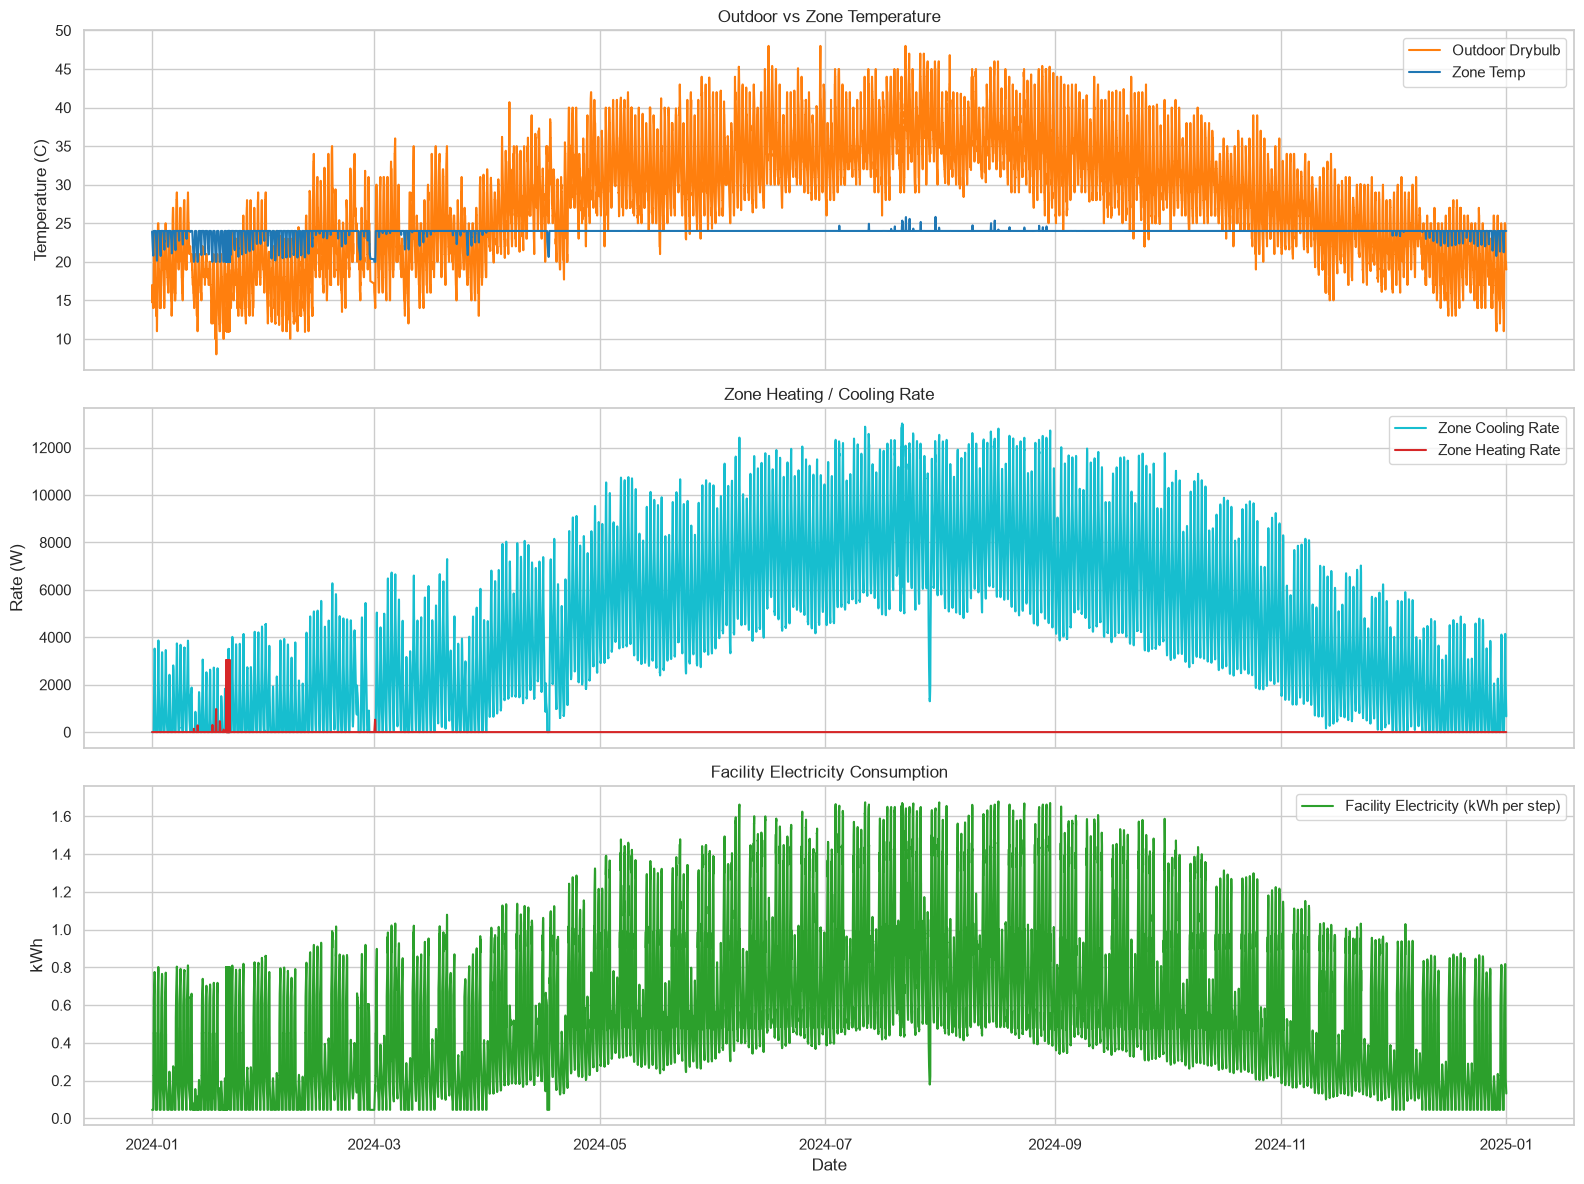

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

axes[0].plot(df["datetime"], df["outdoor_drybulb_C"], color="tab:orange", label="Outdoor Drybulb")
axes[0].plot(df["datetime"], df["zone_temp_C"], color="tab:blue", label="Zone Temp")
axes[0].set_ylabel("Temperature (C)")
axes[0].legend(loc="upper right")
axes[0].set_title("Outdoor vs Zone Temperature")

axes[1].plot(df["datetime"], df["zone_cooling_rate_W"], color="tab:cyan", label="Zone Cooling Rate")
axes[1].plot(df["datetime"], df["zone_heating_rate_W"], color="tab:red", label="Zone Heating Rate")
axes[1].set_ylabel("Rate (W)")
axes[1].legend(loc="upper right")
axes[1].set_title("Zone Heating / Cooling Rate")

axes[2].plot(df["datetime"], df["electricity_facility_J"] / 3.6e6, color="tab:green", label="Facility Electricity (kWh per step)")
axes[2].set_ylabel("kWh")
axes[2].legend(loc="upper right")
axes[2].set_title("Facility Electricity Consumption")
axes[2].set_xlabel("Date")

plt.tight_layout()
plt.show()

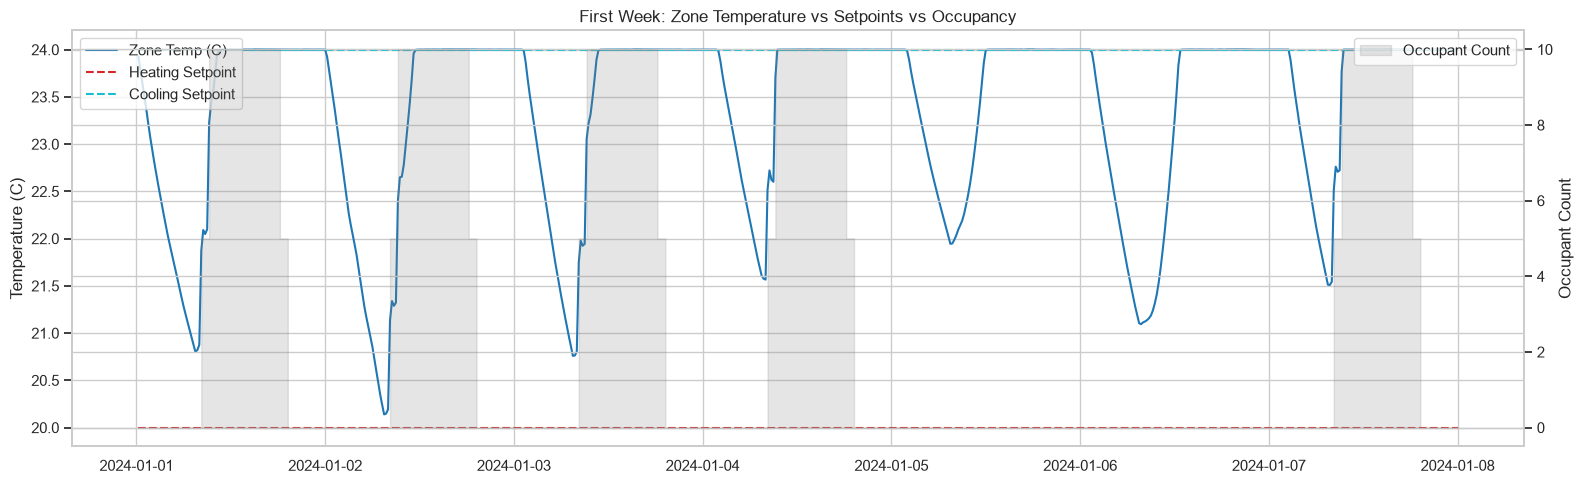

In [14]:
# One representative week for a closer look
start = df["datetime"].min()
week = df[(df["datetime"] >= start) & (df["datetime"] < start + pd.Timedelta(days=7))]

fig, ax1 = plt.subplots(figsize=(16, 5))
ax1.plot(week["datetime"], week["zone_temp_C"], color="tab:blue", label="Zone Temp (C)")
ax1.plot(week["datetime"], week["heating_setpoint_C"], color="tab:red", linestyle="--", label="Heating Setpoint")
ax1.plot(week["datetime"], week["cooling_setpoint_C"], color="tab:cyan", linestyle="--", label="Cooling Setpoint")
ax1.set_ylabel("Temperature (C)")
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
ax2.fill_between(week["datetime"], week["occupant_count"], color="gray", alpha=0.2, step="post", label="Occupant Count")
ax2.set_ylabel("Occupant Count")
ax2.legend(loc="upper right")

plt.title("First Week: Zone Temperature vs Setpoints vs Occupancy")
plt.tight_layout()
plt.show()

## 5. Distributions & Correlation Analysis

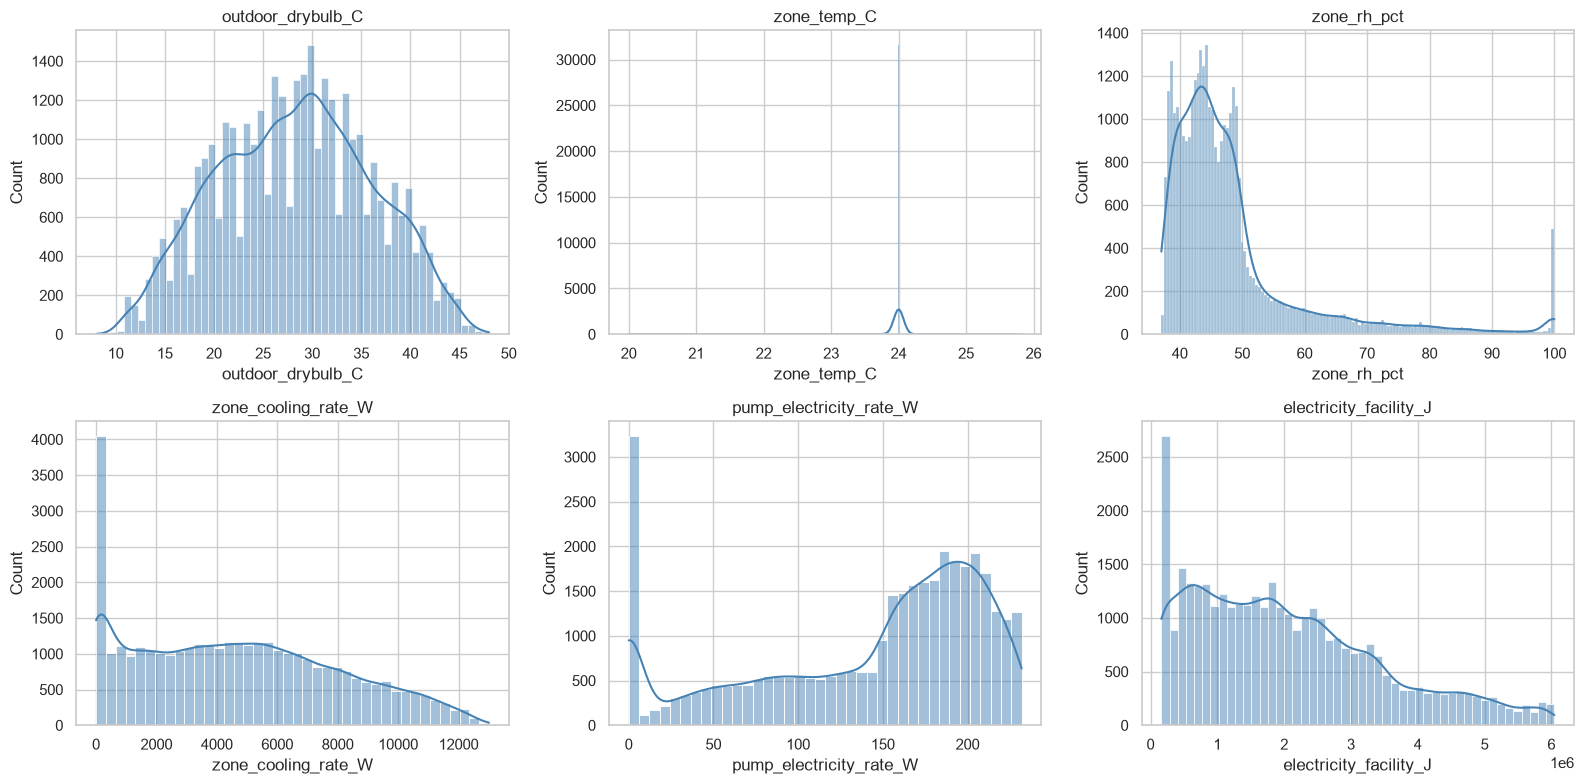

In [15]:
hist_cols = [
    "outdoor_drybulb_C", "zone_temp_C", "zone_rh_pct",
    "zone_cooling_rate_W", "pump_electricity_rate_W", "electricity_facility_J",
]
hist_cols = [c for c in hist_cols if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, hist_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

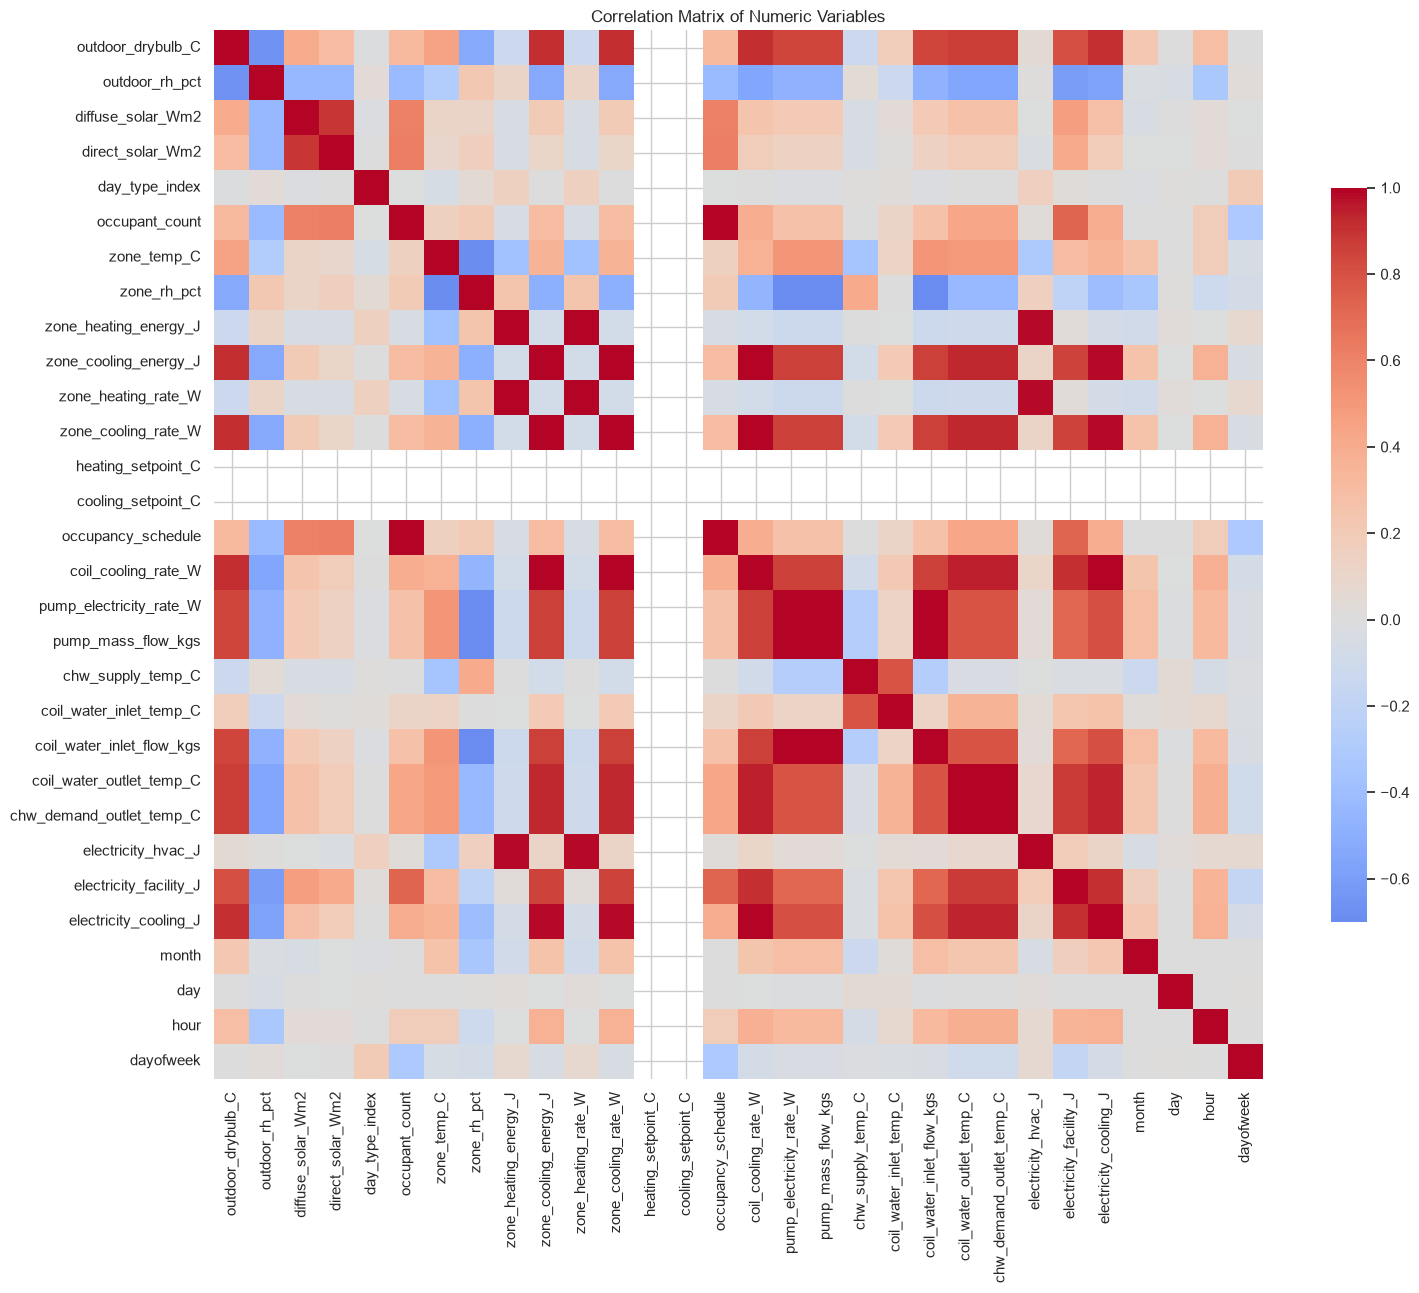

In [16]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[numeric_cols].corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True, cbar_kws={"shrink": 0.7})
plt.title("Correlation Matrix of Numeric Variables")
plt.tight_layout()
plt.show()

In [17]:
target_col = "zone_cooling_rate_W"
top_corr = corr[target_col].drop(target_col).abs().sort_values(ascending=False).head(10)
print(f"Top correlations with {target_col}:")
top_corr

Top correlations with zone_cooling_rate_W:


zone_cooling_energy_J        1.000000
coil_cooling_rate_W          0.992572
electricity_cooling_J        0.980463
coil_water_outlet_temp_C     0.931310
chw_demand_outlet_temp_C     0.931305
outdoor_drybulb_C            0.915811
pump_electricity_rate_W      0.856694
pump_mass_flow_kgs           0.856655
coil_water_inlet_flow_kgs    0.856636
electricity_facility_J       0.853528
Name: zone_cooling_rate_W, dtype: float64

## 6. Daily / Hourly Aggregation Profiles

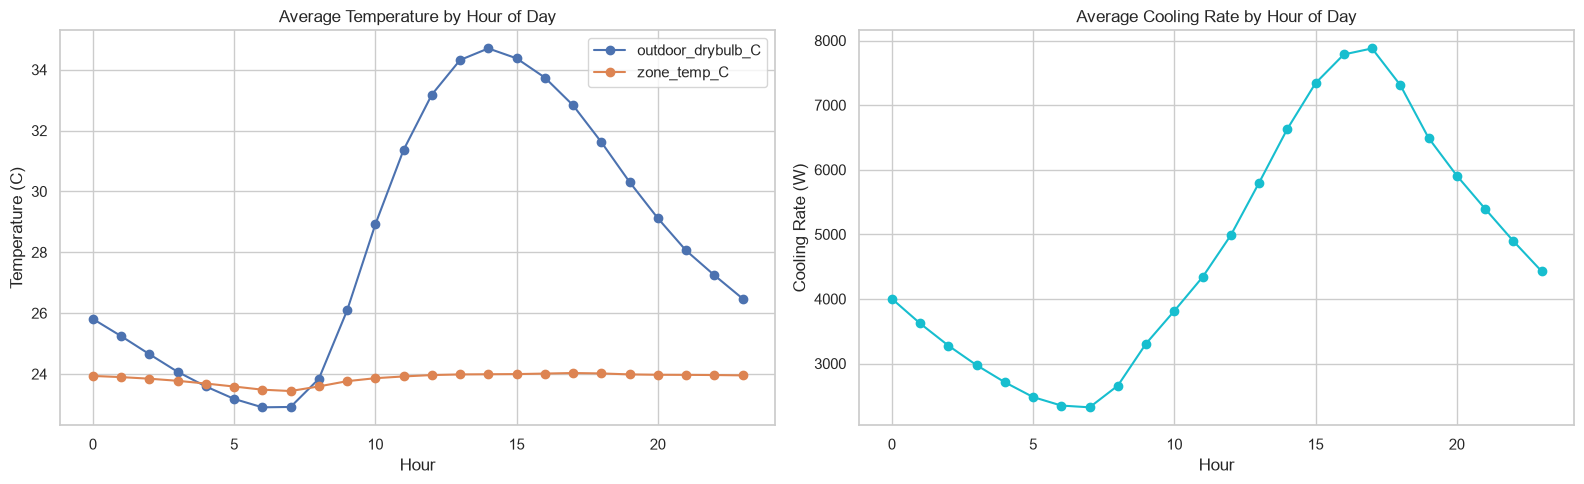

In [18]:
hourly_profile = df.groupby("hour")[["outdoor_drybulb_C", "zone_temp_C", "zone_cooling_rate_W", "occupant_count"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
hourly_profile[["outdoor_drybulb_C", "zone_temp_C"]].plot(ax=axes[0], marker="o")
axes[0].set_title("Average Temperature by Hour of Day")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Temperature (C)")

hourly_profile["zone_cooling_rate_W"].plot(ax=axes[1], marker="o", color="tab:cyan")
axes[1].set_title("Average Cooling Rate by Hour of Day")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Cooling Rate (W)")

plt.tight_layout()
plt.show()

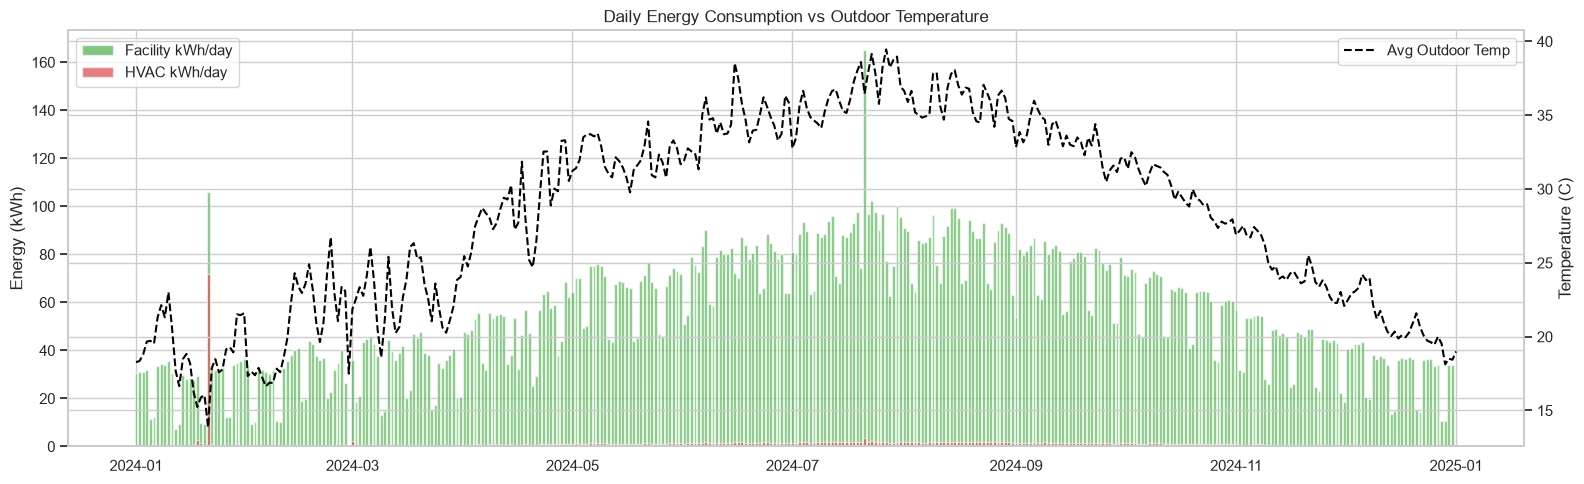

In [19]:
daily = df.set_index("datetime").resample("D").agg({
    "outdoor_drybulb_C": "mean",
    "zone_temp_C": "mean",
    "electricity_facility_J": "sum",
    "electricity_hvac_J": "sum",
})
daily["facility_kWh"] = daily["electricity_facility_J"] / 3.6e6
daily["hvac_kWh"] = daily["electricity_hvac_J"] / 3.6e6

fig, ax1 = plt.subplots(figsize=(16, 5))
ax1.bar(daily.index, daily["facility_kWh"], color="tab:green", alpha=0.6, label="Facility kWh/day")
ax1.bar(daily.index, daily["hvac_kWh"], color="tab:red", alpha=0.6, label="HVAC kWh/day")
ax1.set_ylabel("Energy (kWh)")
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
ax2.plot(daily.index, daily["outdoor_drybulb_C"], color="black", linestyle="--", label="Avg Outdoor Temp")
ax2.set_ylabel("Temperature (C)")
ax2.legend(loc="upper right")

plt.title("Daily Energy Consumption vs Outdoor Temperature")
plt.tight_layout()
plt.show()

## 7. Energy Consumption Breakdown

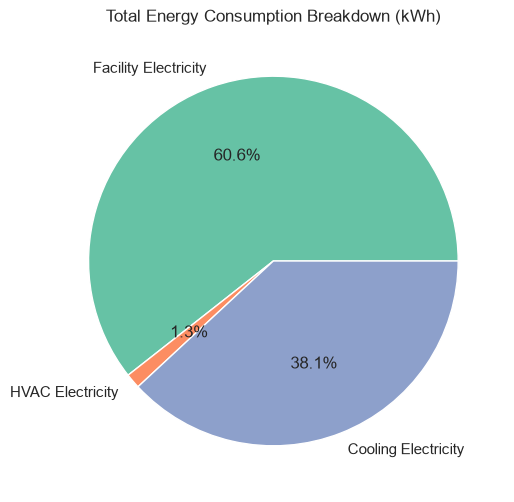

Facility Electricity: 20,104.89 kWh
HVAC Electricity: 435.77 kWh
Cooling Electricity: 12,635.26 kWh


In [20]:
energy_totals_kWh = {
    "Facility Electricity": df["electricity_facility_J"].sum() / 3.6e6,
    "HVAC Electricity": df["electricity_hvac_J"].sum() / 3.6e6,
    "Cooling Electricity": df["electricity_cooling_J"].sum() / 3.6e6,
}

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(energy_totals_kWh.values(), labels=energy_totals_kWh.keys(), autopct="%1.1f%%", colors=sns.color_palette("Set2"))
ax.set_title("Total Energy Consumption Breakdown (kWh)")
plt.show()

for name, value in energy_totals_kWh.items():
    print(f"{name}: {value:,.2f} kWh")

## 8. ML-Readiness Notes

Quick checks useful before building a model (e.g. predicting cooling load / electricity, or an RL environment state space).

In [21]:
# Candidate features vs targets, and basic scale check to flag columns that may need normalization
candidate_features = [
    "outdoor_drybulb_C", "outdoor_rh_pct", "diffuse_solar_Wm2", "direct_solar_Wm2",
    "occupant_count", "occupancy_schedule", "hour", "dayofweek",
]
candidate_targets = ["zone_cooling_rate_W", "zone_temp_C", "electricity_facility_J"]

scale_summary = df[[c for c in candidate_features + candidate_targets if c in df.columns]].agg(["min", "max", "mean", "std"]).T
scale_summary

,min,max,mean,std
outdoor_drybulb_C,8.0,4.800000e+01,2.827246e+01,7.775517e+00
outdoor_rh_pct,10.0,1.000000e+02,5.395195e+01,2.133736e+01
diffuse_solar_Wm2,0.0,4.390000e+02,6.259290e+01,7.499748e+01
direct_solar_Wm2,0.0,9.090000e+02,2.823904e+02,3.328608e+02
occupant_count,0.0,1.000000e+01,2.974569e+00,4.405780e+00
occupancy_schedule,0.0,1.000000e+00,2.974569e-01,4.405780e-01
hour,0.0,2.300000e+01,1.150000e+01,6.922285e+00
dayofweek,0.0,6.000000e+00,3.002413e+00,2.012865e+00
zone_cooling_rate_W,0.0,1.300887e+04,4.696037e+03,3.341811e+03
zone_temp_C,20.0,2.582442e+01,2.385949e+01,5.850616e-01


In [22]:
# Duplicate timestamp / constant column check
print("Duplicate datetimes:", df["datetime"].duplicated().sum())

constant_cols = [c for c in numeric_cols if df[c].nunique(dropna=True) <= 1]
print("Constant columns (no variance, likely uninformative for ML):", constant_cols)

Duplicate datetimes: 192
Constant columns (no variance, likely uninformative for ML): ['heating_setpoint_C', 'cooling_setpoint_C']


In [24]:
# Optionally persist the cleaned, renamed dataframe for downstream ML notebooks
OUTPUT_PATH = Path("/Users/ashanperera/EnergyPlus/UAE_HVAC/output/eplusout_cleaned.csv")
df.to_csv(OUTPUT_PATH, index=False)
print(f"Saved cleaned dataset to {OUTPUT_PATH}")

Saved cleaned dataset to /Users/ashanperera/EnergyPlus/UAE_HVAC/output/eplusout_cleaned.csv
